# Tutorial: KMNet end to end

This notebook demonstrates the usage of **KMNet**, a deep learning model for discrete-time survival analysis with a Kaplan-Meier inspired rank loss.

We will:
1.  Generate synthetic survival data.
2.  Preprocess the data (discretization).
3.  Define and train the `KMNetOptimized` model.
4.  Visualize the predicted survival curves.

In [1]:
# 1. Setup and Imports
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)  # torch.jit.script deprecation notice
warnings.filterwarnings("ignore", category=UserWarning, module="torchtuples")

import torch
import torch.nn as nn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torchtuples as tt
from kmnet import KMNet

# For reproducibility
np.random.seed(42)
_ = torch.manual_seed(42)

## 2. Synthetic Data Generation

We generate a simple dataset where the hazard rate depends on the first feature.
- $X \sim \mathcal{N}(0, 1)$
- $h(t|x) \propto \exp(0.5 x_0)$
- Time to event $T$ is exponential.
- Censoring time $C$ is also exponential.

In [2]:
def make_synthetic_data(n_samples=2000):
    X = np.random.randn(n_samples, 5).astype('float32')
    # Hazard depends on X[:, 0]
    h = 0.1 * np.exp(0.5 * X[:, 0])
    T = np.random.exponential(1/h)
    C = np.random.exponential(1/0.05, size=n_samples)
    time = np.minimum(T, C)
    event = (T <= C).astype('float32')
    return X, time, event

X, time, event = make_synthetic_data()

print(f"X shape: {X.shape}")
print(f"Event rate: {event.mean():.2f}")

# Split into train/test
n_train = 1500
X_train, X_test = X[:n_train], X[n_train:]
time_train, time_test = time[:n_train], time[n_train:]
event_train, event_test = event[:n_train], event[n_train:]

X shape: (2000, 5)
Event rate: 0.65


## 3. Preprocessing

Discrete-time models require discretizing the continuous time variable into bins. We use `label_transforms` from the `pycox` library (which KMNet inherits from) to handle this.

In [3]:
num_durations = 20
labtrans = KMNet.label_transform(num_durations)

get_target = lambda t, e: (t, e)
y_train = labtrans.fit_transform(*get_target(time_train, event_train))
y_test = labtrans.transform(*get_target(time_test, event_test))

print(f"Discretized into {len(labtrans.cuts)} time intervals.")

Discretized into 20 time intervals.


## 4. Model Definition

We define a simple Multi-Layer Perceptron (MLP). The output size must match the number of time bins (`labtrans.out_features`).

In [4]:
in_features = X_train.shape[1]
out_features = labtrans.out_features

net = nn.Sequential(
    nn.Linear(in_features, 32),
    nn.ReLU(),
    nn.Linear(32, 32),
    nn.ReLU(),
    nn.Linear(32, out_features)
)

# Initialize the KMNet model
# We pass the duration index (cuts) so the model knows the time grid
model = KMNet(net, duration_index=labtrans.cuts)

print(net)

Sequential(
  (0): Linear(in_features=5, out_features=32, bias=True)
  (1): ReLU()
  (2): Linear(in_features=32, out_features=32, bias=True)
  (3): ReLU()
  (4): Linear(in_features=32, out_features=20, bias=True)
)


## 5. Training

We train the model using the `fit` method. `KMNet` uses JIT-compiled loss functions for speed.

Trained for 20 epochs; final val loss = 1.0828


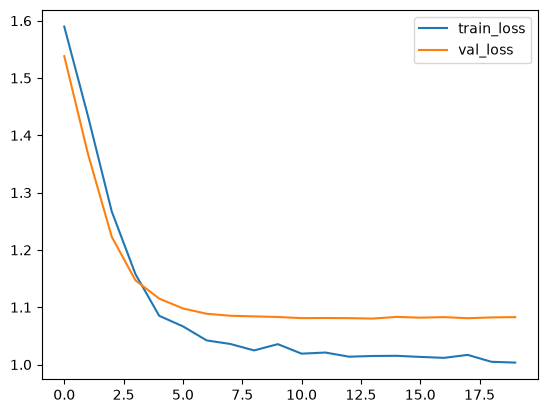

In [5]:
batch_size = 64
epochs = 20
callbacks = [tt.callbacks.EarlyStopping()]

log = model.fit(X_train, y_train, batch_size, epochs, callbacks, val_data=(X_test, y_test), verbose=False)
print(f"Trained for {len(log.to_pandas())} epochs; final val loss = {log.to_pandas().val_loss.iloc[-1]:.4f}")

# Plot training loss
_ = log.plot()

## 6. Prediction and Visualization

We can now predict the survival function $S(t|x)$ for test samples.

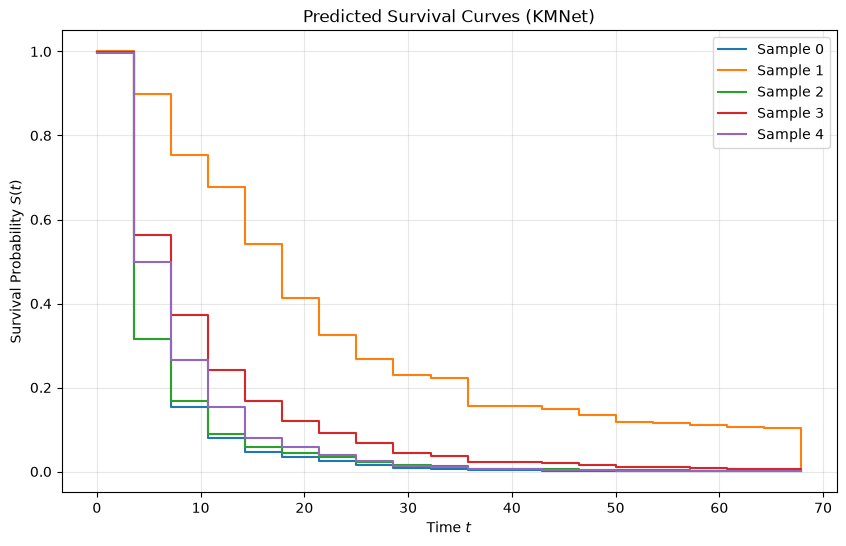

In [6]:
# Predict survival probabilities for the first 5 test samples
surv = model.predict_surv_df(X_test[:5])

# Plot
plt.figure(figsize=(10, 6))
for col in surv.columns:
    plt.step(surv.index, surv[col], where="post", label=f"Sample {col}")

plt.ylabel("Survival Probability $S(t)$")
plt.xlabel("Time $t$")
plt.title("Predicted Survival Curves (KMNet)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## 7. Evaluation

We interpolate the discrete curves and use pycox's `EvalSurv` to compute the time-dependent concordance index and the integrated Brier score on the held-out set.

In [7]:
from pycox.evaluation import EvalSurv
from scipy.integrate import trapezoid

surv_test = model.interpolate(10).predict_surv_df(X_test)
ev = EvalSurv(surv_test, time_test, event_test, censor_surv="km")

time_grid = np.linspace(time_test.min(), np.percentile(time_test, 90), 100)
print(f"Concordance (C-td): {ev.concordance_td('antolini'):.3f}")
# integrate the Brier score curve over the grid (pycox's integrated_brier_score needs SciPy < 1.14)
brier = ev.brier_score(time_grid)
ibs = trapezoid(brier.values, brier.index) / (time_grid[-1] - time_grid[0])
print(f"Integrated Brier score: {ibs:.3f}")

Concordance (C-td): 0.604


Integrated Brier score: 0.198
